<a href="https://colab.research.google.com/github/SarthC/AIML-LAB-/blob/main/Assignment5(B).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
n_students = 50

data = {
    'StudentID': [f'STU{i:03d}' for i in range(1, n_students + 1)],
    'Name': [f'Student {i}' for i in range(1, n_students + 1)],
    'Gender': np.random.choice(['Male', 'Female'], n_students),
    'Maths': np.random.randint(40, 100, n_students),
    'Science': np.random.randint(35, 100, n_students),
    'English': np.random.randint(45, 100, n_students)
}

df = pd.DataFrame(data)
display(df.head())

,StudentID,Name,Gender,Maths,Science,English
0,STU001,Student 1,Male,86,96,76
1,STU002,Student 2,Female,90,48,48
2,STU003,Student 3,Male,83,82,74
3,STU004,Student 4,Male,94,49,81
4,STU005,Student 5,Male,91,96,67


In [2]:
df['Total'] = df[['Maths', 'Science', 'English']].sum(axis=1)
df['Percentage'] = round(df['Total'] / 3, 2)

def assign_grade(pct):
    if pct >= 85: return 'A'
    elif pct >= 70: return 'B'
    elif pct >= 50: return 'C'
    else: return 'F'

df['Grade'] = df['Percentage'].apply(assign_grade)
display(df.head())

print("Summary Statistics:")
display(df.describe())

,StudentID,Name,Gender,Maths,Science,English,Total,Percentage,Grade
0,STU001,Student 1,Male,86,96,76,258,86.00,A
1,STU002,Student 2,Female,90,48,48,186,62.00,C
2,STU003,Student 3,Male,83,82,74,239,79.67,B
3,STU004,Student 4,Male,94,49,81,224,74.67,B
4,STU005,Student 5,Male,91,96,67,254,84.67,B


Summary Statistics:


,Maths,Science,English,Total,Percentage
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,70.240000,66.100000,73.040000,209.380000,69.793600
std,19.246585,20.133483,15.363567,33.769259,11.256955
min,41.000000,35.000000,45.000000,125.000000,41.670000
25%,53.000000,48.000000,60.250000,186.000000,62.000000
50%,73.500000,67.500000,74.000000,212.500000,70.835000
75%,88.250000,81.750000,85.750000,236.500000,78.832500
max,99.000000,99.000000,99.000000,272.000000,90.670000


/tmp/ipykernel_5168/1822329301.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Gender', y='Percentage', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_5168/1822329301.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Grade', order=['A', 'B', 'C', 'F'], ax=axes[1, 0], palette='pastel')


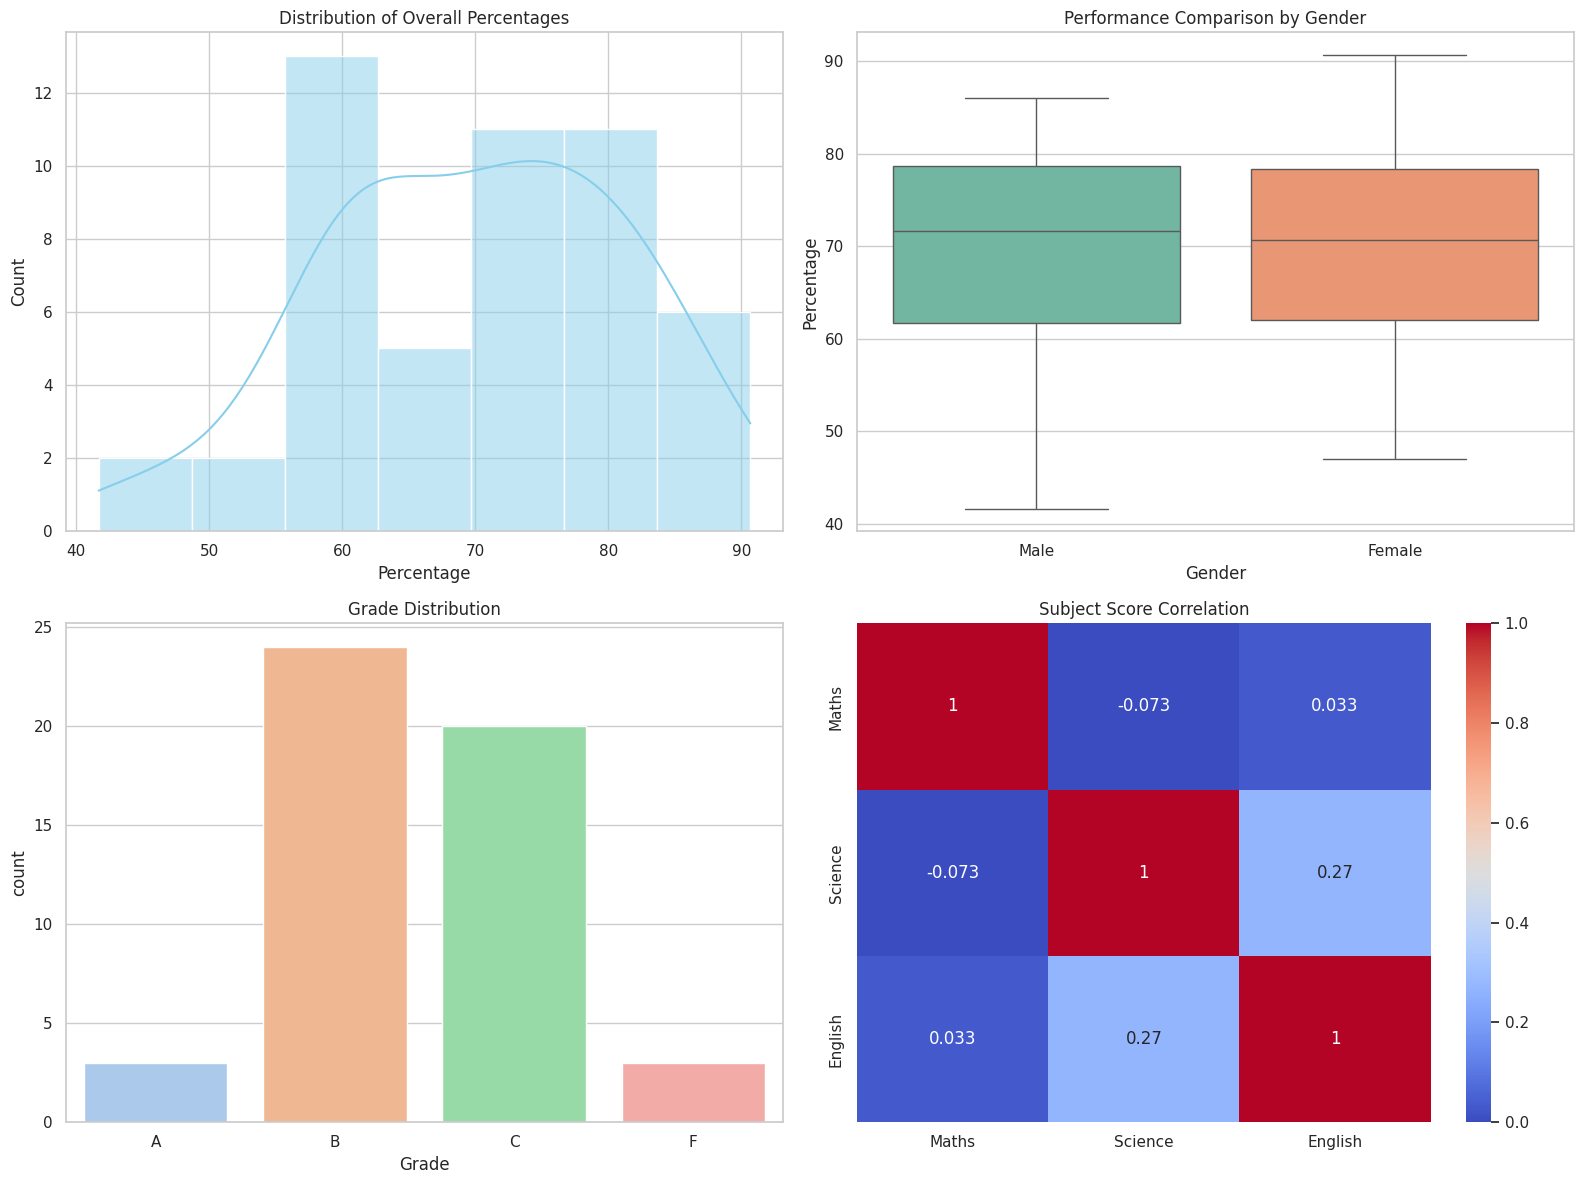

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.histplot(df['Percentage'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Overall Percentages')
axes[0, 0].set_xlabel('Percentage')

sns.boxplot(data=df, x='Gender', y='Percentage', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Performance Comparison by Gender')

sns.countplot(data=df, x='Grade', order=['A', 'B', 'C', 'F'], ax=axes[1, 0], palette='pastel')
axes[1, 0].set_title('Grade Distribution')

corr = df[['Maths', 'Science', 'English']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', ax=axes[1, 1], vmin=0, vmax=1)
axes[1, 1].set_title('Subject Score Correlation')

plt.tight_layout()
plt.show()